In [36]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [38]:
df = pd.read_csv('./Classified Data')

In [39]:
df.head()

,Unnamed: 0,WTT,PTI,EQW,SBI,LQE,QWG,FDJ,PJF,HQE,NXJ,TARGET CLASS
0,0,0.913917,1.162073,0.567946,0.755464,0.780862,0.352608,0.759697,0.643798,0.879422,1.231409,1
1,1,0.635632,1.003722,0.535342,0.825645,0.924109,0.648450,0.675334,1.013546,0.621552,1.492702,0
2,2,0.721360,1.201493,0.921990,0.855595,1.526629,0.720781,1.626351,1.154483,0.957877,1.285597,0
3,3,1.234204,1.386726,0.653046,0.825624,1.142504,0.875128,1.409708,1.380003,1.522692,1.153093,1
4,4,1.279491,0.949750,0.627280,0.668976,1.232537,0.703727,1.115596,0.646691,1.463812,1.419167,1


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    1000 non-null   int64  
 1   WTT           1000 non-null   float64
 2   PTI           1000 non-null   float64
 3   EQW           1000 non-null   float64
 4   SBI           1000 non-null   float64
 5   LQE           1000 non-null   float64
 6   QWG           1000 non-null   float64
 7   FDJ           1000 non-null   float64
 8   PJF           1000 non-null   float64
 9   HQE           1000 non-null   float64
 10  NXJ           1000 non-null   float64
 11  TARGET CLASS  1000 non-null   int64  
dtypes: float64(10), int64(2)
memory usage: 93.9 KB


In [41]:
df.describe()

,Unnamed: 0,WTT,PTI,EQW,SBI,LQE,QWG,FDJ,PJF,HQE,NXJ,TARGET CLASS
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,499.500000,0.949682,1.114303,0.834127,0.682099,1.032336,0.943534,0.963422,1.071960,1.158251,1.362725,0.50000
std,288.819436,0.289635,0.257085,0.291554,0.229645,0.243413,0.256121,0.255118,0.288982,0.293738,0.204225,0.50025
min,0.000000,0.174412,0.441398,0.170924,0.045027,0.315307,0.262389,0.295228,0.299476,0.365157,0.639693,0.00000
25%,249.750000,0.742358,0.942071,0.615451,0.515010,0.870855,0.761064,0.784407,0.866306,0.934340,1.222623,0.00000
50%,499.500000,0.940475,1.118486,0.813264,0.676835,1.035824,0.941502,0.945333,1.065500,1.165556,1.375368,0.50000
75%,749.250000,1.163295,1.307904,1.028340,0.834317,1.198270,1.123060,1.134852,1.283156,1.383173,1.504832,1.00000
max,999.000000,1.721779,1.833757,1.722725,1.634884,1.650050,1.666902,1.713342,1.785420,1.885690,1.893950,1.00000


<Axes: >

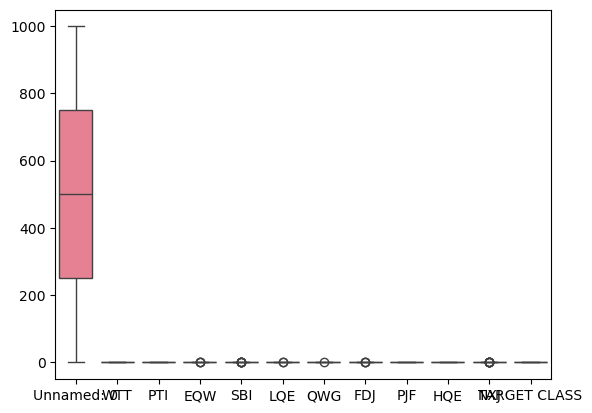

In [42]:
sns.boxplot(df)

In [43]:
df.columns

Index(['Unnamed: 0', 'WTT', 'PTI', 'EQW', 'SBI', 'LQE', 'QWG', 'FDJ', 'PJF',
       'HQE', 'NXJ', 'TARGET CLASS'],
      dtype='object')

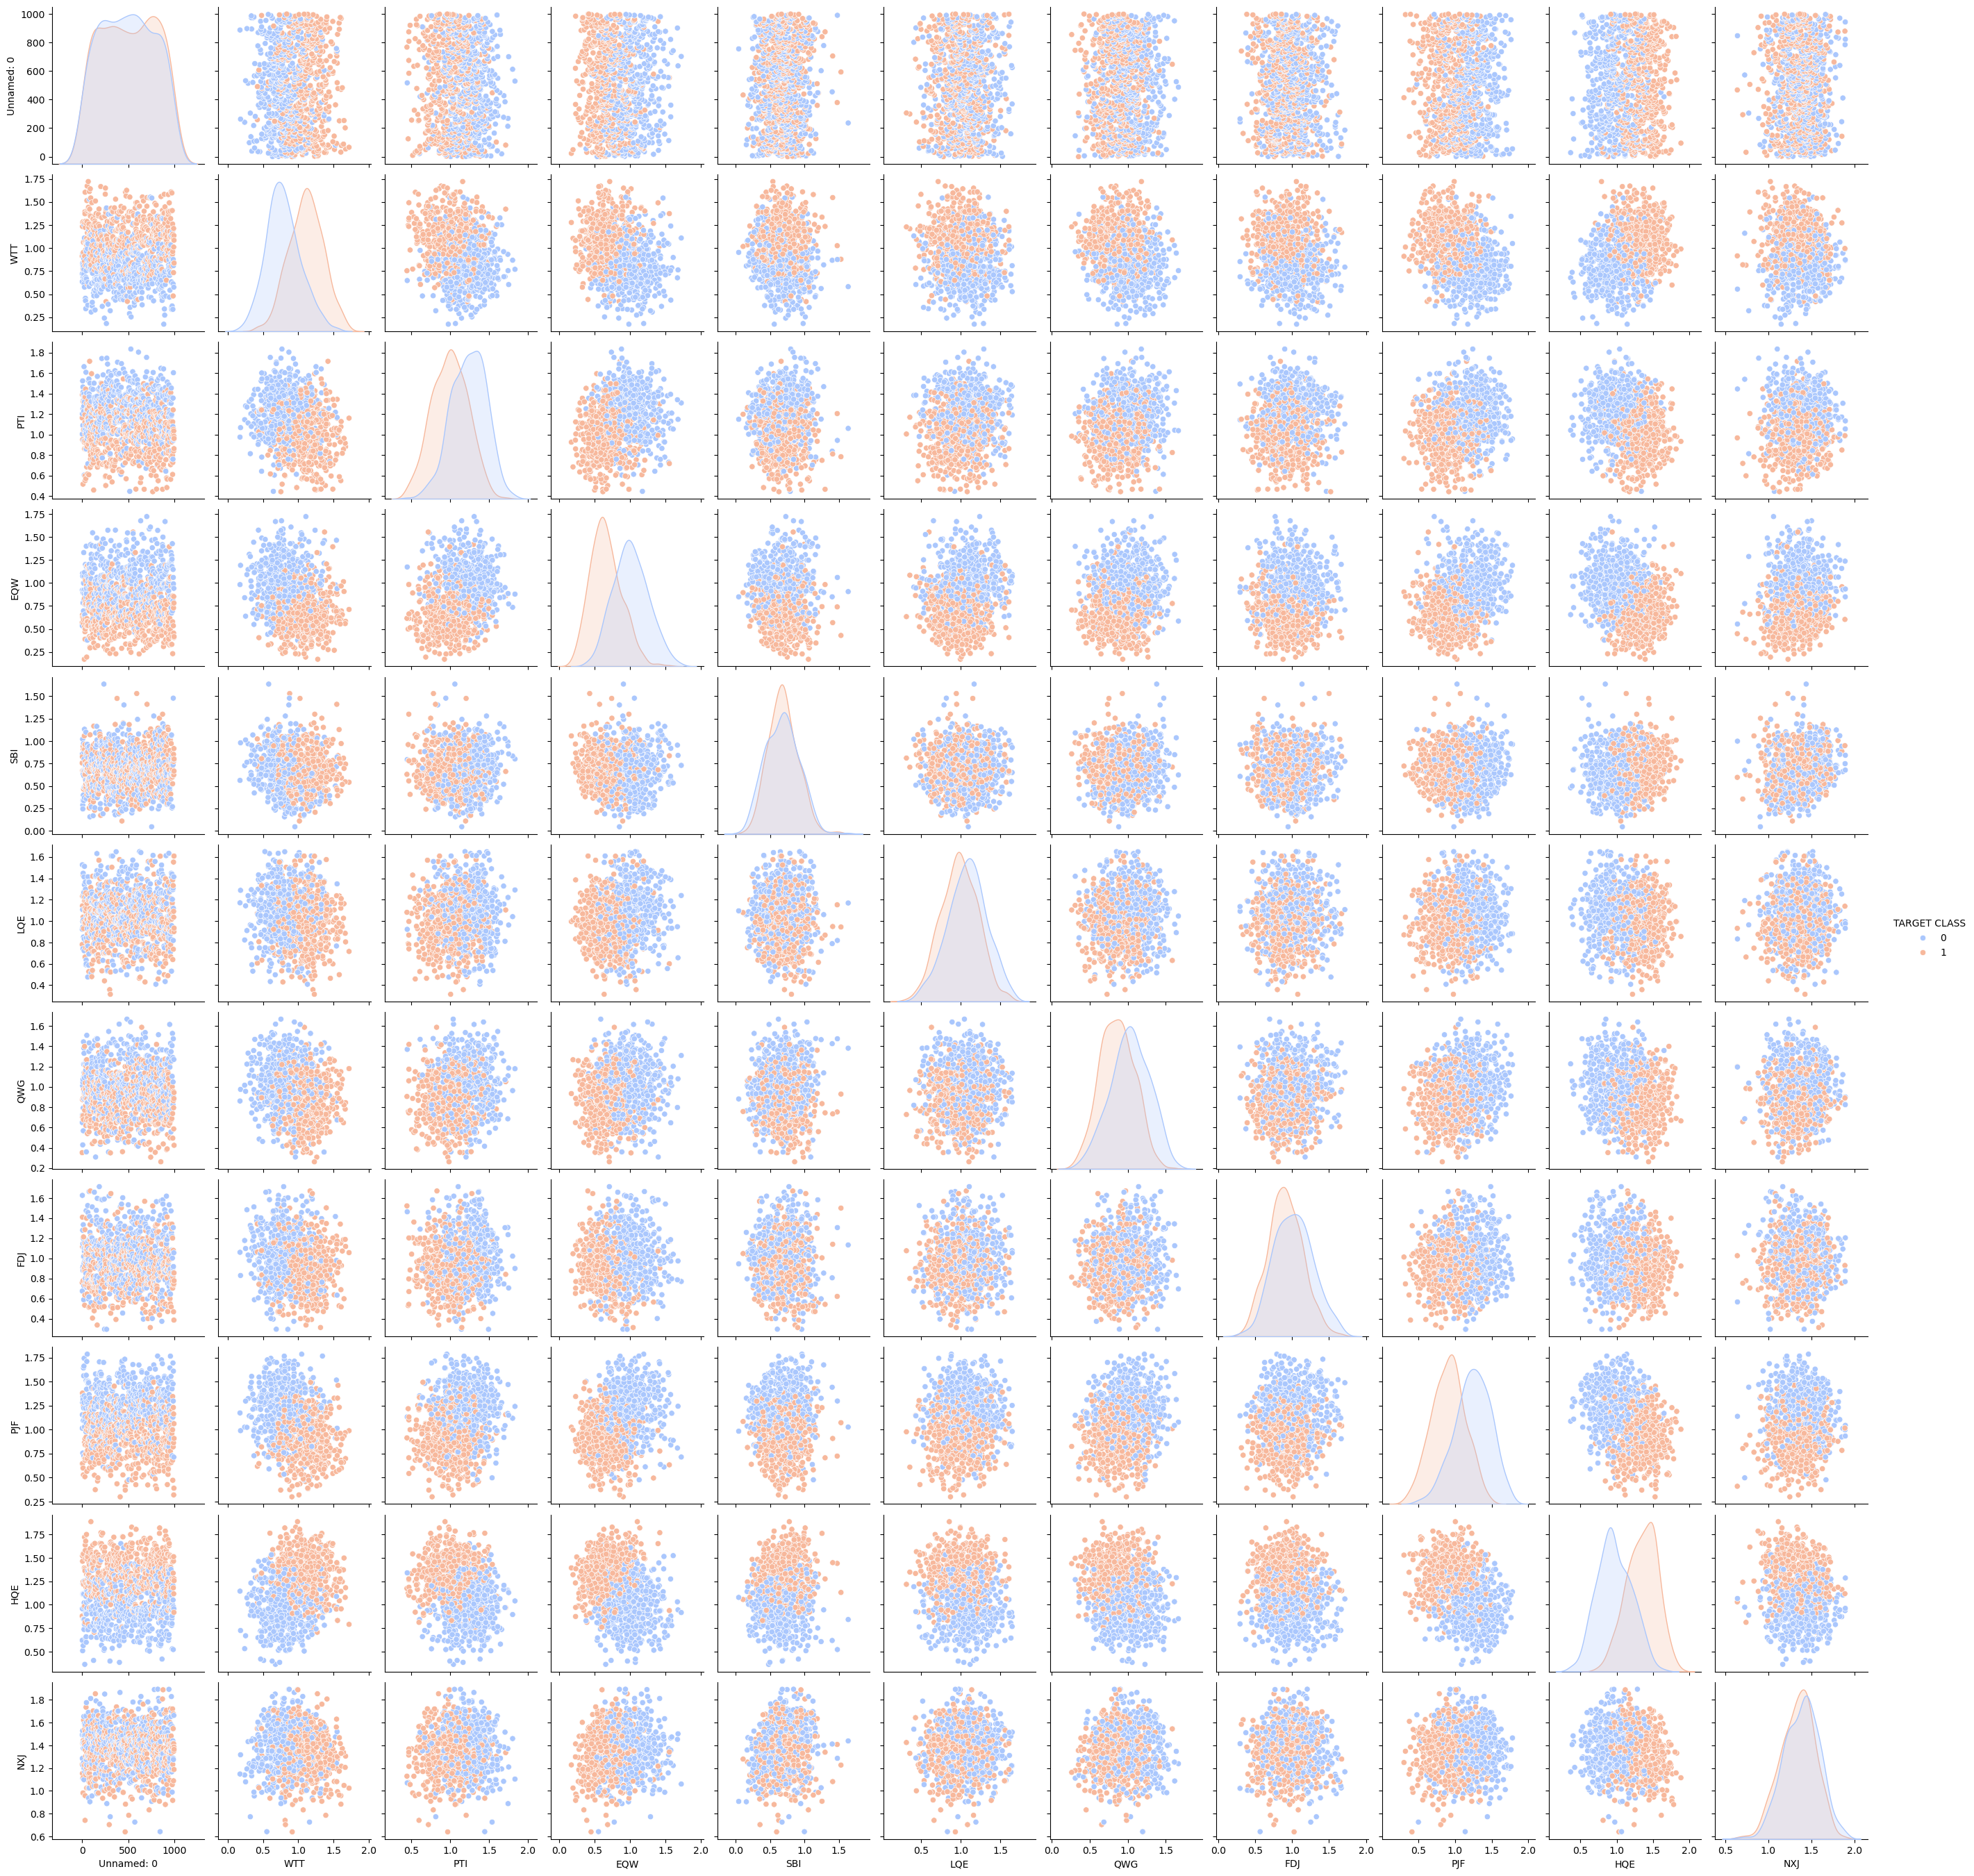

In [44]:
sns.pairplot(df, hue='TARGET CLASS', palette='coolwarm')
plt.show()

## Preprocessing

In [45]:
X_train,X_test,y_train,y_test = train_test_split(df.drop(columns='TARGET CLASS'), df['TARGET CLASS'], test_size=0.3, random_state=42)

In [46]:
scaler = StandardScaler()
scaler.fit(X_train)
scaled_train = scaler.transform(X_train)
scaled_test = scaler.transform(X_test)

In [48]:
df1 = pd.DataFrame(scaled_train, columns=df.columns[:-1])

In [49]:
df1.head()

,Unnamed: 0,WTT,PTI,EQW,SBI,LQE,QWG,FDJ,PJF,HQE,NXJ
0,0.143479,-0.609059,0.058835,0.336657,-1.663372,-0.195120,-1.121921,-0.069944,-0.850078,0.483777,0.311313
1,-0.208437,-0.742329,0.032494,0.290180,-0.222340,1.813965,0.267395,-1.956671,-0.036618,-1.006906,0.594092
2,-0.062096,0.732400,0.688311,0.880453,-0.901065,0.590600,-1.478840,0.619649,0.218707,-1.304123,0.888006
3,-0.271155,1.745343,-1.296576,-0.277813,-0.426003,0.159944,-1.529778,0.173955,-0.261237,0.774244,0.128933
4,0.969262,-0.476898,1.381447,0.211398,2.595139,0.107935,0.729850,-0.386245,2.091412,-0.722307,0.184804


In [50]:
knn = KNeighborsClassifier(n_neighbors=1)

In [51]:
knn.fit(scaled_train,y_train)

KNeighborsClassifier(n_neighbors=1)

In [52]:
pred = knn.predict(scaled_test)

In [53]:
from sklearn.metrics import classification_report,confusion_matrix

In [54]:
print(classification_report(y_test,pred))

              precision    recall  f1-score   support

           0       0.90      0.93      0.92       142
           1       0.94      0.91      0.92       158

    accuracy                           0.92       300
   macro avg       0.92      0.92      0.92       300
weighted avg       0.92      0.92      0.92       300



In [55]:
print(confusion_matrix(y_test,pred))

[[132  10]
 [ 14 144]]


## Elbow method

In [56]:
error_rate = []

for i in range(1,40):
    knnn = KNeighborsClassifier(n_neighbors=i)
    knnn.fit(scaled_train,y_train)
    pred_i = knnn.predict(scaled_test)
    error_rate.append(np.mean(pred_i != y_test))

Text(0, 0.5, 'Error Rate')

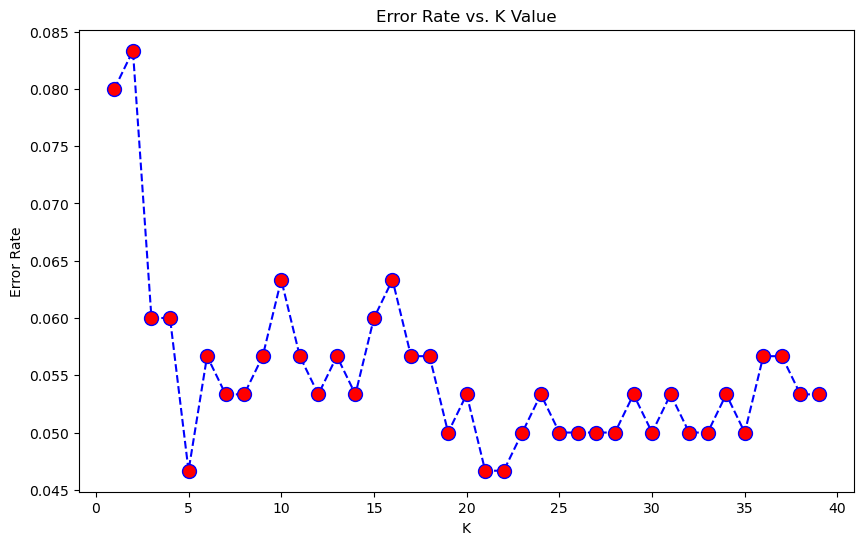

In [57]:
plt.figure(figsize=(10,6))
plt.plot(range(1,40),error_rate,color='blue', linestyle='dashed', marker='o',
         markerfacecolor='red', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')

In [58]:
knn = KNeighborsClassifier(n_neighbors=5)

In [60]:
knn.fit(scaled_train,y_train)
pred = knn.predict(scaled_test)

In [61]:
print(confusion_matrix(y_test,pred))

[[136   6]
 [  8 150]]


In [62]:
print(classification_report(y_test,pred))

              precision    recall  f1-score   support

           0       0.94      0.96      0.95       142
           1       0.96      0.95      0.96       158

    accuracy                           0.95       300
   macro avg       0.95      0.95      0.95       300
weighted avg       0.95      0.95      0.95       300



In [63]:
knn = KNeighborsClassifier(n_neighbors=21)
knn.fit(scaled_train,y_train)
pred = knn.predict(scaled_test)

In [65]:
print(confusion_matrix(y_test,pred))

[[136   6]
 [  8 150]]


In [66]:
print(classification_report(y_test,pred))

              precision    recall  f1-score   support

           0       0.94      0.96      0.95       142
           1       0.96      0.95      0.96       158

    accuracy                           0.95       300
   macro avg       0.95      0.95      0.95       300
weighted avg       0.95      0.95      0.95       300

